In [2]:
# import necessary libraries
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

## Question 1
Use the data in homework_10.1.csv and find the fixed effect (the constant term in the regression) for each time (0 through 11). Which of these describes the pattern: 

- A: The effects gradually increase from month 0 to 11. 

- B: The effects vary randomly.

- C: The effects increase from month 0 to about 5 or 6 but then eventually decrease again.

- D: The effects decrease from month 0 to about 5 or 6 but then eventually increase again.

In [3]:
df = pd.read_csv('../data/homework_10.1.csv')
df.head()

,city,time,X,y
0,0,0,0.144044,7.552716
1,0,1,1.454274,10.077829
2,0,2,0.761038,12.372731
3,0,3,0.121675,11.489263
4,0,4,0.443863,13.104833


In [4]:
X = sm.add_constant(df[["X", "time"]])
Y = df["y"]
model = smf.ols("Y ~ X + C(time)", data=df).fit()
print(f"Model summary:\n{model.summary()}")

Model summary:
                            OLS Regression Results                            
Dep. Variable:                      Y   R-squared:                       0.241
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     9.167
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           2.26e-15
Time:                        23:43:11   Log-Likelihood:                -1012.6
No. Observations:                 360   AIC:                             2051.
Df Residuals:                     347   BIC:                             2102.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         2.8792      0

In [5]:
print (f"Model coefficients:\n{model.params}")

Model coefficients:
Intercept        2.879246
C(time)[T.1]     1.797612
C(time)[T.2]     3.269013
C(time)[T.3]     4.283751
C(time)[T.4]     5.238644
C(time)[T.5]     6.137104
C(time)[T.6]     5.747063
C(time)[T.7]     5.636421
C(time)[T.8]     5.528032
C(time)[T.9]     4.588259
C(time)[T.10]    3.112496
C(time)[T.11]    1.743903
X                1.238139
dtype: float64


In [6]:
model = smf.ols("Y ~ X + C(time) - 1", data=df).fit()

print(model.params)

C(time)[0]     2.879246
C(time)[1]     4.676858
C(time)[2]     6.148259
C(time)[3]     7.162997
C(time)[4]     8.117890
C(time)[5]     9.016350
C(time)[6]     8.626309
C(time)[7]     8.515667
C(time)[8]     8.407278
C(time)[9]     7.467505
C(time)[10]    5.991741
C(time)[11]    4.623149
X              1.238139
dtype: float64


In [7]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.241
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     9.167
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           2.26e-15
Time:                        23:43:12   Log-Likelihood:                -1012.6
No. Observations:                 360   AIC:                             2051.
Df Residuals:                     347   BIC:                             2102.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
C(time)[0]      2.8792      0.752      3.830      0.000       1.401       4.358
C(time)[1]      4.6769      0.750      6.237      0.000       3.202       6.152
C(time)[2]      6.1483      0.750      8.192      0.000       4.672       7.624
C(time)[3]      7.1630      0.749      9.558      0.000       5.689       8.637
C(time)[4]      8.1179      0.750     10.831      0.000       6.644       9.592
C(time)[5]      9.0164      0.750     12.027      0.000       7.542      10.491
C(time)[6]      8.6263      0.750     11.505      0.000       7.152      10.101
C(time)[7]      8.5157      0.750     11.349      0.000       7.040       9.991
C(time)[8]      8.4073      0.752     11.182      0.000       6.928       9.886
C(time)[9]      7.4675      0.752      9.929      0.000       5.988       8.947
C(time)[10]     5.9917      0.754      7.943      0.000       4.508       7.475
C(time)[11]     4.6231      0.750      6.166      0.000       3.148       6.098
X               1.2381      0.226      5.479      0.000       0.794       1.683
==============================================================================
Omnibus:                       45.306   Durbin-Watson:                   0.291
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               12.564
Skew:                          -0.041   Prob(JB):                      0.00187
Kurtosis:                       2.088   Cond. No.                         3.47
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Answer :   C   
_________

## Question 2
What about the fixed effect for each city (0 through 9)? 

- A: The effects gradually increase from city 0 to 9.

- B: The effects vary randomly.

- C: The effects increase from city 0 to about 4 or 5 but then eventually decrease again.

- D: The effects decrease from city 0 to about 4 or 5 but then eventually increase again. 

In [8]:
model_city = smf.ols("y ~ X + C(city) - 1",data=df).fit()

city_effects = pd.Series({c: model_city.params[f"C(city)[{c}]"]for c in range(10)})

print("City Fixed Effects:")
print(city_effects.round(4))

City Fixed Effects:
0    11.0299
1     5.2271
2     7.9218
3    12.9260
4    11.2960
5    -0.0578
6     7.7050
7     3.2576
8     3.3840
9     5.4504
dtype: float64


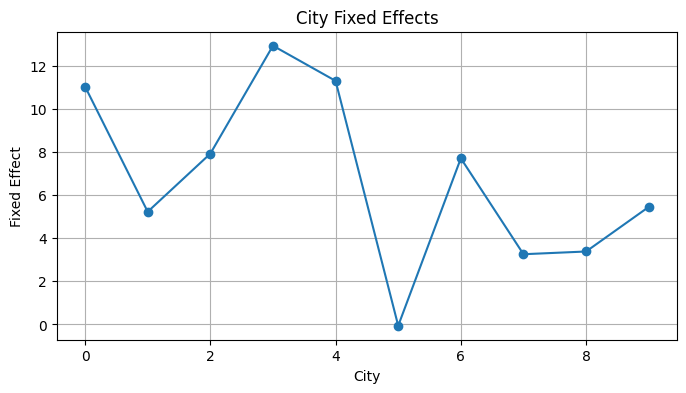

In [9]:
city_effects.plot(marker="o", figsize=(8, 4), grid=True)
plt.title("City Fixed Effects")
plt.xlabel("City")
plt.ylabel("Fixed Effect")
plt.show()

Answer :  B   
_________

## Question 3
For the following data, model np.exp(Y) as a function of X and Z.    
With enough data, the coefficients of X and Z are closest to: 

- A: Both 1 

- B: Both 1.3 

- C: Both 1.6

- D: Both 2.5

In [10]:
num = 10000 

X = np.clip(np.random.normal(3, 1, (num,)), 0.01, 100)

Z = np.clip(np.random.normal(3, 1, (num,)), 0.01, 100)

Y = np.log(X + Z) + np.random.normal(0, 1, (num,)) 


In [11]:
model = smf.ols("np.exp(Y) ~ X + Z",data={"Y": Y, "X": X, "Z": Z}).fit()

print(model.params)

Intercept    0.822834
X            1.666236
Z            1.274464
dtype: float64


Answer :   C   
_________

## Question 4
Suppose we were to use the data below to find the standard error of X's coefficient (the coefficient that should be 1.5) in two ways: 

1)  By asking Python to find the standard error. 

2)  By simulating what happens if we generate the data 100 times, estimating X's coefficient and finding the standard deviation of the 100 estimates, using this model:     
      
      
- A: 1 is significantly bigger than 2, but neither is zero. 

- B: 2 is significantly bigger than 1, but neither is zero.

- C: They are about the same. 

- D: One or both of them are zero.


In [12]:
num = 10000 

Z = np.random.normal(0, 1, (num,)) 

X = Z + np.random.normal(0, 1, (num,)) 

Y = 1.5 * X + 2.3 * Z + np.random.normal(0, X**2, (num,)) 

In [ ]:
# Summary of the simple ols model with heteroskedasticity
smf.ols("Y ~ X + Z", data=pd.DataFrame({"Y": Y, "X": X, "Z": Z})).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.579
Model:                            OLS   Adj. R-squared:                  0.579
Method:                 Least Squares   F-statistic:                     6863.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:43:12   Log-Likelihood:                -26713.
No. Observations:               10000   AIC:                         5.343e+04
Df Residuals:                    9997   BIC:                         5.345e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.0308      0.035      0.879      0.379      -0.038       0.099
X              1.5095      0.035     42.869      0.000       1.440       1.578
Z              2.2498      0.049     46.015      0.000       2.154       2.346
==============================================================================
Omnibus:                     2841.835   Durbin-Watson:                   2.019
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           371417.330
Skew:                          -0.020   Prob(JB):                         0.00
Kurtosis:                      32.856   Cond. No.                         2.62
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [14]:
# coefficients and standard errors of X in 100 simulations
coefficients = []

for _ in range(100):
    num = 10000
    Z = np.random.normal(0, 1, num)
    X = Z + np.random.normal(0, 1, num)
    Y = 1.5 * X + 2.3 * Z + np.random.normal(0, X**2, num)

    fit = smf.ols("Y ~ X + Z",data=pd.DataFrame({"Y": Y, "X": X, "Z": Z})).fit()

    coefficients.append(fit.params["X"])

std_error = np.std(coefficients)
print(std_error)


0.05422571192017293


Answer :   B   
_________

In [15]:
# optional computation of the OLS model with heteroskedasticity-robust standard errors
# compute the OLS model with heteroskedasticity-robust standard errors( when the variance of the error term is not constant across observations, in this case, the variance of the error term is proportional to X^2)
model = sm.OLS(Y, sm.add_constant(np.column_stack([X, Z]))).fit(cov_type="HC3")
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.584
Model:                            OLS   Adj. R-squared:                  0.584
Method:                 Least Squares   F-statistic:                     2231.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        23:43:12   Log-Likelihood:                -26648.
No. Observations:               10000   AIC:                         5.330e+04
Df Residuals:                    9997   BIC:                         5.332e+04
Df Model:                           2                                         
Covariance Type:                  HC3                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0110      0.035     -0.316      0.752      -0.079       0.057
x1             1.5109      0.058     26.105      0.000       1.397       1.624
x2             2.2670      0.048     47.334      0.000       2.173       2.361
==============================================================================
Omnibus:                     2907.840   Durbin-Watson:                   1.998
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           271575.106
Skew:                          -0.376   Prob(JB):                         0.00
Kurtosis:                      28.519   Cond. No.                         2.67
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""